In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from lightgbm import LGBMRegressor

In [56]:
BASE_DIR = Path("..").resolve()

data_file = BASE_DIR / "datasets" / "amez_dataset_cleaned.xlsx"
elasticity_file = BASE_DIR / "datasets" / "elasticity_features.xlsx"

model_folder = (
    BASE_DIR
    / "backend"
    / "ml"
    / "pricing"
    / "models"
)

model_folder.mkdir(parents=True, exist_ok=True)

print("Project folder:")
print(BASE_DIR)

print("\nMain dataset:")
print(data_file)

print("\nElasticity dataset:")
print(elasticity_file)

print("\nModel folder:")
print(model_folder)

Project folder:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform

Main dataset:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\datasets\amez_dataset_cleaned.xlsx

Elasticity dataset:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\datasets\elasticity_features.xlsx

Model folder:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\pricing\models


In [57]:
data = pd.read_excel(
    data_file,
    sheet_name="Overall_Transactions"
)

print("Dataset shape:", data.shape)

data.head()

Dataset shape: (11992, 14)


,InvoiceID,InvoiceDate,CustomerID,ProductID,ProductName,Category,SubCategory,Quantity,UnitPrice,Discount,TotalAmount,StockQuantity,StoreID,StoreName
0,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,8e4669ab-db13-4000-0bd7-f03200008e46,Merino Wool Minimalist Crewneck Knitwear,Fashion & Apparel,Men's Fashion,1,11500.0,2000,9500.0,75,9abc0803-cfe9-4000-0a98-919a00009abc,Luxe Apparel Studio
1,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,Beauty & Wellness,Skincare Essentials,2,6800.0,2000,11600.0,115,9fbc0fe2-cae9-4000-0ac8-967b00009fbc,Glow Naturals Cosmetics
2,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,7ec257a3-2b97-4000-04df-ce3a00007ec2,Velocity Pro Carbon Running Sneakers,Fashion & Apparel,Footwear,2,17500.0,4000,31000.0,95,a0bc1175-f5e9-4000-0938-88ec0000a0bc,Velocity Athletic Gear
3,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,81c25c5c-d497-4000-0b2f-c5c5000081c2,Ergonomic Breathable Mesh Desk Chair,Home & Living,Modern Furniture,1,28000.0,4000,24000.0,50,99bc0670-cce9-4000-0aa8-9fe9000099bc,Nordic Living Essentials
4,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,Beauty & Wellness,Skincare Essentials,1,6800.0,1000,5800.0,115,9fbc0fe2-cae9-4000-0ac8-967b00009fbc,Glow Naturals Cosmetics


In [58]:
print("Columns:")

for column in data.columns:
    print(column)

Columns:
InvoiceID
InvoiceDate
CustomerID
ProductID
ProductName
Category
SubCategory
Quantity
UnitPrice
Discount
TotalAmount
StockQuantity
StoreID
StoreName


In [59]:
missing_values = data.isnull().sum()

print(missing_values)

InvoiceID        0
InvoiceDate      0
CustomerID       0
ProductID        0
ProductName      0
Category         0
SubCategory      0
Quantity         0
UnitPrice        0
Discount         0
TotalAmount      0
StockQuantity    0
StoreID          0
StoreName        0
dtype: int64


In [60]:
missing_values = data.isnull().sum()

print(missing_values)

InvoiceID        0
InvoiceDate      0
CustomerID       0
ProductID        0
ProductName      0
Category         0
SubCategory      0
Quantity         0
UnitPrice        0
Discount         0
TotalAmount      0
StockQuantity    0
StoreID          0
StoreName        0
dtype: int64


In [61]:
print(
    "Missing InvoiceDate:",
    data["InvoiceDate"].isna().sum()
)

Missing InvoiceDate: 0


In [62]:
data = data.dropna(
    subset=["InvoiceDate"]
).copy()

print("Shape after removing invalid dates:", data.shape)

Shape after removing invalid dates: (11992, 14)


In [63]:
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "Discount",
    "EffectivePrice",
    "StockQuantity"
]

for column in numeric_columns:
    if column in data.columns:
        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )

In [64]:
data = data.dropna(
    subset=["Quantity"]
).copy()

data = data[
    data["Quantity"] > 0
].copy()

print("Dataset shape:", data.shape)

print("\nQuantity statistics:")
print(data["Quantity"].describe())

Dataset shape: (11992, 14)

Quantity statistics:
count    11992.000000
mean         2.363159
std          1.243026
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: Quantity, dtype: float64


In [65]:
data["DayOfWeek"] = data["InvoiceDate"].dt.dayofweek

data["Month"] = data["InvoiceDate"].dt.month

data["Day"] = data["InvoiceDate"].dt.day

data["Year"] = data["InvoiceDate"].dt.year

In [66]:
data[
    [
        "InvoiceDate",
        "DayOfWeek",
        "Month",
        "Day",
        "Year"
    ]
].head()

,InvoiceDate,DayOfWeek,Month,Day,Year
0,2026-01-01,3,1,1,2026
1,2026-01-01,3,1,1,2026
2,2026-01-01,3,1,1,2026
3,2026-01-01,3,1,1,2026
4,2026-01-01,3,1,1,2026


In [67]:
print(
    "Unique years:",
    data["Year"].nunique()
)

print(
    "Years:",
    sorted(data["Year"].unique())
)

Unique years: 1
Years: [np.int32(2026)]


In [68]:
elasticity_data = pd.read_excel(
    elasticity_file
)

print(
    "Elasticity dataset shape:",
    elasticity_data.shape
)

elasticity_data.head()

Elasticity dataset shape: (11992, 8)


,ProductID,InvoiceDate,Quantity,UnitPrice,Discount,EffectivePrice,PriceChange,DemandChange
0,0128933d-9879-4346-aafc-a8045c36b087,2026-01-15 05:51:38,2,34267.0,500,34017.000000,NaN,NaN
1,0128933d-9879-4346-aafc-a8045c36b087,2026-01-16 06:21:19,4,34748.0,0,34748.000000,0.021489,1.0
2,0128933d-9879-4346-aafc-a8045c36b087,2026-01-16 06:30:27,2,32309.0,2000,31309.000000,-0.098970,-0.5
3,0128933d-9879-4346-aafc-a8045c36b087,2026-01-17 06:55:34,2,34283.0,0,34283.000000,0.094989,0.0
4,0128933d-9879-4346-aafc-a8045c36b087,2026-01-19 07:52:39,3,33196.0,4000,31862.666667,-0.070599,0.5


In [69]:
print("Elasticity columns:")

for column in elasticity_data.columns:
    print(column)

Elasticity columns:
ProductID
InvoiceDate
Quantity
UnitPrice
Discount
EffectivePrice
PriceChange
DemandChange


In [70]:
elasticity_data["EffectivePrice"] = pd.to_numeric(
    elasticity_data["EffectivePrice"],
    errors="coerce"
)

elasticity_data["Quantity"] = pd.to_numeric(
    elasticity_data["Quantity"],
    errors="coerce"
)

elasticity_data = elasticity_data.dropna(
    subset=[
        "ProductID",
        "EffectivePrice",
        "Quantity"
    ]
).copy()

elasticity_data = elasticity_data[
    (elasticity_data["EffectivePrice"] > 0) &
    (elasticity_data["Quantity"] > 0)
].copy()

print(
    "Clean elasticity dataset:",
    elasticity_data.shape
)

Clean elasticity dataset: (11989, 8)


In [71]:
price_demand = (
    elasticity_data
    .groupby(
        [
            "ProductID",
            "EffectivePrice"
        ],
        as_index=False
    )
    .agg(
        TotalDemand=("Quantity", "sum"),
        SalesObservations=("InvoiceDate", "count")
    )
)

price_demand.head()

,ProductID,EffectivePrice,TotalDemand,SalesObservations
0,0128933d-9879-4346-aafc-a8045c36b087,29113.0,1,1
1,0128933d-9879-4346-aafc-a8045c36b087,29117.0,1,1
2,0128933d-9879-4346-aafc-a8045c36b087,30027.0,2,1
3,0128933d-9879-4346-aafc-a8045c36b087,30160.0,2,1
4,0128933d-9879-4346-aafc-a8045c36b087,30184.0,2,1


In [72]:
def estimate_elasticity(product_data):
    
    product_data = product_data[
        (product_data["EffectivePrice"] > 0) &
        (product_data["TotalDemand"] > 0)
    ].copy()

    product_data = product_data.drop_duplicates(
        subset=["EffectivePrice"]
    )

    if len(product_data) < 3:
        return None

    log_price = np.log(
        product_data["EffectivePrice"]
    )

    log_demand = np.log(
        product_data["TotalDemand"]
    )

    slope = np.polyfit(
        log_price,
        log_demand,
        1
    )[0]

    return float(slope)

In [73]:
elasticity_results = []

for product_id, group in price_demand.groupby("ProductID"):

    elasticity = estimate_elasticity(group)

    elasticity_results.append({
        "ProductID": product_id,
        "Elasticity": elasticity,
        "PriceObservations": group[
            "EffectivePrice"
        ].nunique()
    })

elasticity_df = pd.DataFrame(
    elasticity_results
)

print(
    "Products with elasticity estimates:",
    len(elasticity_df)
)

elasticity_df.head()

Products with elasticity estimates: 121


,ProductID,Elasticity,PriceObservations
0,0128933d-9879-4346-aafc-a8045c36b087,3.746624,88
1,03df1a4a-b5a2-40ee-b621-f064b782d4a1,1.676465,96
2,04df7b21-ab56-460d-96c8-25aed6e602a0,2.169678,89
3,06a13e3b-0b08-40f7-bc7c-74fc8f197b7f,2.217897,73
4,0a7982e2-2a56-4dea-b738-821ef43ca9ae,2.750905,78


In [74]:
print(
    elasticity_df["Elasticity"].describe()
)

count    121.000000
mean       2.455890
std        1.108801
min       -0.453240
25%        1.700429
50%        2.598637
75%        3.348075
max        4.782789
Name: Elasticity, dtype: float64


In [75]:
print(
    "Missing elasticity:",
    elasticity_df["Elasticity"].isna().sum()
)

Missing elasticity: 0


In [76]:
model_data = data.merge(
    elasticity_df[
        [
            "ProductID",
            "Elasticity"
        ]
    ],
    on="ProductID",
    how="left"
)

print(
    "Model dataset shape:",
    model_data.shape
)

Model dataset shape: (11992, 19)


In [77]:
model_data = data.copy()

model_data["EffectivePrice"] = (
    model_data["UnitPrice"] -
    model_data["Discount"]
)

print(
    "Model dataset shape:",
    model_data.shape
)

model_data[
    [
        "ProductID",
        "ProductName",
        "UnitPrice",
        "Discount",
        "EffectivePrice",
        "StockQuantity",
        "Quantity"
    ]
].head(10)

Model dataset shape: (11992, 19)


,ProductID,ProductName,UnitPrice,Discount,EffectivePrice,StockQuantity,Quantity
0,8e4669ab-db13-4000-0bd7-f03200008e46,Merino Wool Minimalist Crewneck Knitwear,11500.0,2000,9500.0,75,1
1,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,6800.0,2000,4800.0,115,2
2,7ec257a3-2b97-4000-04df-ce3a00007ec2,Velocity Pro Carbon Running Sneakers,17500.0,4000,13500.0,95,2
3,81c25c5c-d497-4000-0b2f-c5c5000081c2,Ergonomic Breathable Mesh Desk Chair,28000.0,4000,24000.0,50,1
4,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,6800.0,1000,5800.0,115,1
5,85c262a8-d097-4000-0b6f-fb31000085c2,All-Terrain 4-Season Ultralight Tent,31500.0,9000,22500.0,45,2
6,83c25f82-d697-4000-0b0f-c61b000083c2,Hand-Blown Sculptural Glass Pendant Lamp,12500.0,2000,10500.0,60,1
7,81c25c5c-d497-4000-0b2f-c5c5000081c2,Ergonomic Breathable Mesh Desk Chair,28000.0,8000,20000.0,50,2
8,90c92fbe-c59c-4000-0a3f-b627000090c9,Golden Glow Organic Rosehip Face Oil,4500.0,700,3800.0,160,1
9,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,6800.0,2000,4800.0,115,2


In [78]:
model_data = model_data.merge(
    elasticity_df[
        [
            "ProductID",
            "Elasticity"
        ]
    ],
    on="ProductID",
    how="left"
)

print(
    "Model dataset shape after elasticity merge:",
    model_data.shape
)

Model dataset shape after elasticity merge: (11992, 20)


In [79]:
model_data[
    [
        "ProductID",
        "ProductName",
        "EffectivePrice",
        "StockQuantity",
        "Elasticity",
        "Quantity"
    ]
].head(10)

,ProductID,ProductName,EffectivePrice,StockQuantity,Elasticity,Quantity
0,8e4669ab-db13-4000-0bd7-f03200008e46,Merino Wool Minimalist Crewneck Knitwear,9500.0,75,2.212905,1
1,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,4800.0,115,1.741449,2
2,7ec257a3-2b97-4000-04df-ce3a00007ec2,Velocity Pro Carbon Running Sneakers,13500.0,95,4.045802,2
3,81c25c5c-d497-4000-0b2f-c5c5000081c2,Ergonomic Breathable Mesh Desk Chair,24000.0,50,1.910538,1
4,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,5800.0,115,1.741449,1
5,85c262a8-d097-4000-0b6f-fb31000085c2,All-Terrain 4-Season Ultralight Tent,22500.0,45,3.112607,2
6,83c25f82-d697-4000-0b0f-c61b000083c2,Hand-Blown Sculptural Glass Pendant Lamp,10500.0,60,2.964330,1
7,81c25c5c-d497-4000-0b2f-c5c5000081c2,Ergonomic Breathable Mesh Desk Chair,20000.0,50,1.910538,2
8,90c92fbe-c59c-4000-0a3f-b627000090c9,Golden Glow Organic Rosehip Face Oil,3800.0,160,0.655260,1
9,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,4800.0,115,1.741449,2


In [80]:
print(
    "Missing elasticity:",
    model_data["Elasticity"].isna().sum()
)

print(
    "Total rows:",
    len(model_data)
)

Missing elasticity: 0
Total rows: 11992


In [81]:
elasticity_median = model_data[
    "Elasticity"
].median()

print(
    "Median elasticity:",
    elasticity_median
)

Median elasticity: 2.712063595554656


In [82]:
features = [
    "EffectivePrice",
    "Discount",
    "DayOfWeek",
    "Month",
    "Day",
    "StockQuantity",
    "Elasticity",
    "ProductID",
    "Category",
    "SubCategory",
    "StoreID"
]

In [83]:
missing_features = [
    feature
    for feature in features
    if feature not in model_data.columns
]

print("Missing features:", missing_features)

Missing features: []


In [84]:
X = model_data[features].copy()

y = model_data["Quantity"].copy()

print("X shape:", X.shape)

print("y shape:", y.shape)

X shape: (11992, 11)
y shape: (11992,)


In [85]:
valid_rows = (
    X.notna().all(axis=1) &
    y.notna()
)

X = X.loc[valid_rows].copy()

y = y.loc[valid_rows].copy()

print("Final X shape:", X.shape)

print("Final y shape:", y.shape)

Final X shape: (11992, 11)
Final y shape: (11992,)


In [86]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))

print("Testing rows:", len(X_test))

Training rows: 9593
Testing rows: 2399


In [87]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

In [88]:
model.fit(
    X_train,
    y_train,
    categorical_feature=[
        "ProductID",
        "Category",
        "SubCategory",
        "StoreID"
    ]
)

ValueError: pandas dtypes must be int, float or bool.
Fields with bad pandas dtypes: ProductID: str, Category: str, SubCategory: str, StoreID: str

In [ ]:
y_pred = model.predict(X_test)

print("First 10 predictions:")

print(y_pred[:10])

First 10 predictions:
[1.73211556 3.43656301 1.83262784 2.27867334 1.84634667 1.397124
 2.79374473 2.906846   3.09055841 2.18950178]


In [ ]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE:", round(mae, 3))

print("RMSE:", round(rmse, 3))

print("R²:", round(r2, 3))

MAE: 1.0
RMSE: 1.234
R²: 0.032


In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(20)

,Actual,Predicted
0,1,1.732116
1,4,3.436563
2,3,1.832628
3,5,2.278673
4,1,1.846347
5,1,1.397124
6,1,2.793745
7,1,2.906846
8,5,3.090558
9,4,2.189502


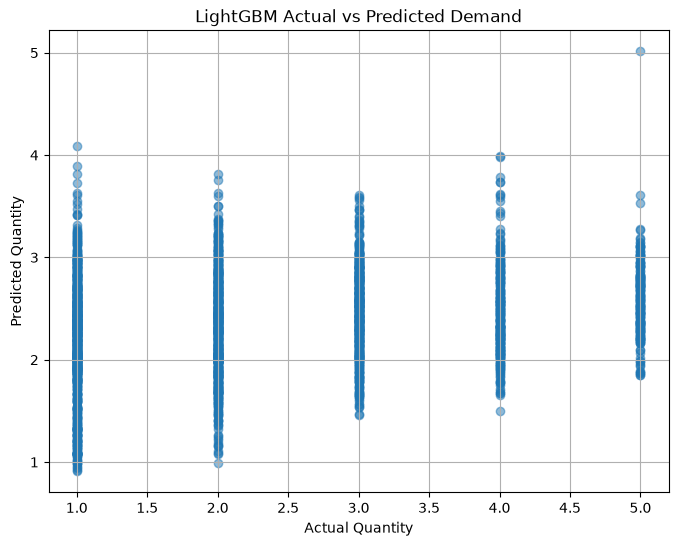

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Actual Quantity")

plt.ylabel("Predicted Quantity")

plt.title(
    "LightGBM Actual vs Predicted Demand"
)

plt.grid(True)

plt.show()

In [ ]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
5,StockQuantity,1946
7,ProductID,1600
4,Day,1274
0,EffectivePrice,1090
1,Discount,668
3,Month,609
2,DayOfWeek,579
10,StoreID,278
6,Elasticity,222
9,SubCategory,110


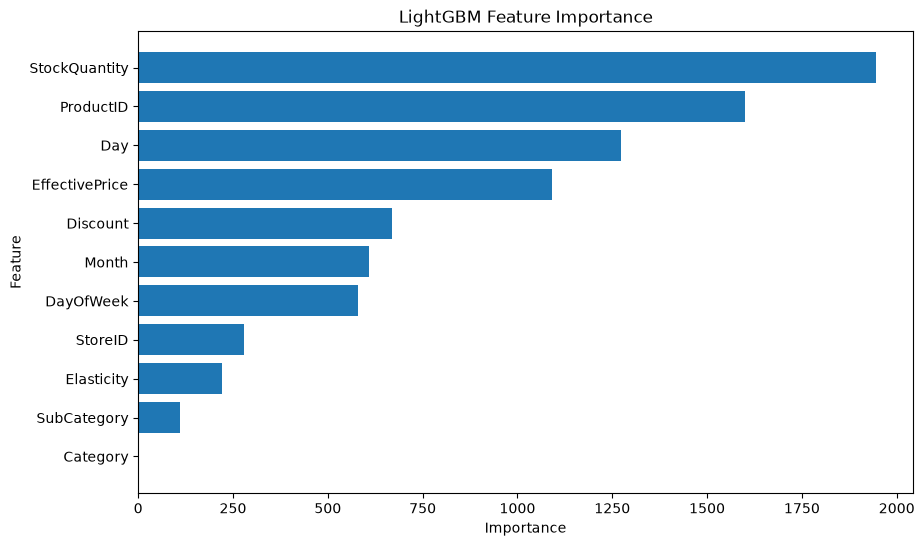

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.title(
    "LightGBM Feature Importance"
)

plt.gca().invert_yaxis()

plt.show()

In [ ]:
model_path = (
    model_folder
    / "lightgbm_demand_model.pkl"
)

joblib.dump(
    model,
    model_path
)

print(
    "Model saved to:"
)

print(model_path)

Model saved to:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\pricing\models\lightgbm_demand_model.pkl


In [ ]:
features_path = (
    model_folder
    / "pricing_features.pkl"
)

joblib.dump(
    features,
    features_path
)

print(
    "Feature list saved to:"
)

print(features_path)

Feature list saved to:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\pricing\models\pricing_features.pkl


In [ ]:
categorical_path = (
    model_folder
    / "pricing_categorical_features.pkl"
)

categorical_features = [
    "ProductID",
    "Category",
    "SubCategory",
    "StoreID"
]

joblib.dump(
    categorical_features,
    categorical_path
)

print(
    "Categorical feature list saved to:"
)

print(categorical_path)

Categorical feature list saved to:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\pricing\models\pricing_categorical_features.pkl


In [ ]:
metrics = {
    "MAE": float(mae),
    "RMSE": float(rmse),
    "R2": float(r2)
}

metrics_path = (
    model_folder
    / "lightgbm_metrics.pkl"
)

joblib.dump(
    metrics,
    metrics_path
)

print(
    "Metrics saved to:"
)

print(metrics_path)

Metrics saved to:
C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\pricing\models\lightgbm_metrics.pkl


In [ ]:
print("Saved model files:")

for file in model_folder.iterdir():
    print(file.name)

Saved model files:
lightgbm_demand_model.pkl
lightgbm_metrics.pkl
pricing_categorical_features.pkl
pricing_features.pkl


In [ ]:
loaded_model = joblib.load(
    model_path
)

loaded_features = joblib.load(
    features_path
)

print("Model loaded successfully.")

print("\nFeatures:")

print(loaded_features)

Model loaded successfully.

Features:
['EffectivePrice', 'Discount', 'DayOfWeek', 'Month', 'Day', 'StockQuantity', 'Elasticity', 'ProductID', 'Category', 'SubCategory', 'StoreID']


In [ ]:
sample_data = X_test.iloc[:5].copy()

sample_predictions = loaded_model.predict(
    sample_data
)

print(
    "Sample predictions:"
)

print(sample_predictions)

Sample predictions:
[1.73211556 3.43656301 1.83262784 2.27867334 1.84634667]


In [ ]:
print(model_data.columns.tolist())
print(data.columns.tolist())
print(elasticity_data.columns.tolist())

['InvoiceID', 'InvoiceDate', 'CustomerID', 'ProductID', 'ProductName', 'Category', 'SubCategory', 'Quantity', 'UnitPrice', 'Discount', 'TotalAmount', 'StockQuantity', 'StoreID', 'StoreName', 'DayOfWeek', 'Month', 'Day', 'Year', 'EffectivePrice', 'Elasticity']
['InvoiceID', 'InvoiceDate', 'CustomerID', 'ProductID', 'ProductName', 'Category', 'SubCategory', 'Quantity', 'UnitPrice', 'Discount', 'TotalAmount', 'StockQuantity', 'StoreID', 'StoreName', 'DayOfWeek', 'Month', 'Day', 'Year']
['ProductID', 'InvoiceDate', 'Quantity', 'UnitPrice', 'Discount', 'EffectivePrice', 'PriceChange', 'DemandChange']
